# Tiền xử lý dữ liệu House Prices (Ames Housing)
**Nội dung:** 2.2 Outlier Detection · 2.3 Categorical Data · 2.4 Numerical Data  
**Sản phẩm:** dataset đã tiền xử lý (`train_processed.csv`, `test_processed.csv`) sẵn sàng đưa vào mô hình.

Nguyên tắc xuyên suốt: **mọi tham số (ngưỡng cắt outlier, bộ mã hóa, scaler) chỉ được học (fit) trên tập train**, sau đó áp dụng (transform) cho tập test để tránh rò rỉ dữ liệu.

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import RepeatedKFold, KFold, cross_val_score
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

DATA_DIR = Path('/mnt/user-data/uploads') if Path('/mnt/user-data/uploads/train.csv').exists() else Path('.')
OUT_DIR = Path('output'); FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 'SalePrice'
R = {}   # lưu kết quả chính để dùng cho báo cáo Word

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=130, bbox_inches='tight'); plt.show()

## 0. Đọc dữ liệu và xử lý giá trị thiếu (điều kiện tiên quyết)
Outlier, encoding và scaling đều không chạy được khi còn `NaN`, nên bước này xử lý tối thiểu:
- Với các cột mà `NaN` nghĩa là **"không có"** (không có hầm, gara, hồ bơi, hàng rào...) → điền `"None"`.
- `LotFrontage` → median theo `Neighborhood`; `GarageYrBlt` → `YearBuilt`; các cột diện tích/số lượng của hầm/gara → 0.
- Còn lại → median (số) / mode (chữ) **của tập train**.

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
print('train:', train.shape, '| test:', test.shape)
R['shape_raw'] = {'train': list(train.shape), 'test': list(test.shape)}
R['missing_raw'] = int(train.isna().sum().sum()), int(test.isna().sum().sum())

none_cols = ['Alley','MasVnrType','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2',
             'FireplaceQu','GarageType','GarageFinish','GarageQual','GarageCond','PoolQC','Fence','MiscFeature']
zero_cols = ['MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath',
             'GarageCars','GarageArea']

lot_med = train.groupby('Neighborhood')['LotFrontage'].median()
def fill_missing(df, ref):
    df = df.copy()
    for c in none_cols: df[c] = df[c].fillna('None')
    for c in zero_cols: df[c] = df[c].fillna(0)
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lot_med)).fillna(ref['LotFrontage'].median())
    # GarageYrBlt: thiếu hoặc sai (vd. năm 2207 trong test) -> lấy YearBuilt
    bad = df['GarageYrBlt'].isna() | (df['GarageYrBlt'] > 2010)
    df.loc[bad, 'GarageYrBlt'] = df.loc[bad, 'YearBuilt']
    for c in df.columns:
        if c == TARGET or df[c].notna().all(): continue
        df[c] = df[c].fillna(ref[c].median() if pd.api.types.is_numeric_dtype(ref[c]) else ref[c].mode()[0])
    return df

train = fill_missing(train, train); test = fill_missing(test, train)
print('Còn NaN -> train:', train.drop(columns=TARGET).isna().sum().sum(), '| test:', test.isna().sum().sum())

train: (1460, 81) | test: (1459, 80)
Còn NaN -> train: 0 | test: 0


---
# 2.2 Outlier Detection
## 2.2.1 Chọn nhóm biến để kiểm tra
Chỉ kiểm tra outlier trên **biến liên tục** (diện tích, độ dài). Không áp dụng cho:
- biến định danh mã số (`MSSubClass`), biến thứ hạng 1–10 (`OverallQual`, `OverallCond`), biến đếm nhỏ, biến năm;
- `Id` và `SalePrice` (SalePrice được phân tích riêng như biến mục tiêu).

In [3]:
cont_cols = ['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF',
             '1stFlrSF','2ndFlrSF','LowQualFinSF','GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF',
             'EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal']
print(len(cont_cols), 'biến liên tục được kiểm tra')

19 biến liên tục được kiểm tra


## 2.2.2 Phương pháp IQR và Z-score
- **IQR:** `Q1 − 1.5·IQR` đến `Q3 + 1.5·IQR`; điểm nằm ngoài là outlier.
- **Z-score:** `z = (x − mean)/std`; điểm có `|z| > 3` là outlier.

Hai lưu ý quan trọng: (1) với biến có >75% giá trị bằng 0 (hiên, hồ bơi, MiscVal...) thì `IQR = 0`, mọi giá trị khác 0 đều bị gắn nhãn outlier — đó là *"zero-inflated"* chứ không phải lỗi; (2) Z-score dùng mean/std vốn đã bị outlier kéo lệch nên có thể bỏ sót.

In [4]:
rows = []
for c in cont_cols:
    x = train[c]; q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = (x - x.mean()) / x.std()
    rows.append(dict(feature=c, Q1=q1, Q3=q3, IQR=iqr, lower=lo, upper=hi,
                     n_IQR=int(((x < lo) | (x > hi)).sum()), n_Z=int((z.abs() > 3).sum()),
                     zero_ratio=round((x == 0).mean(), 3), skew=round(x.skew(), 2)))
out_tab = pd.DataFrame(rows).set_index('feature')
out_tab['pct_IQR'] = (out_tab.n_IQR / len(train) * 100).round(2)
out_tab['pct_Z'] = (out_tab.n_Z / len(train) * 100).round(2)
R['outlier_table'] = out_tab.reset_index().to_dict('records')
out_tab[['Q1','Q3','IQR','lower','upper','n_IQR','pct_IQR','n_Z','pct_Z','zero_ratio','skew']]

,Q1,Q3,IQR,lower,upper,n_IQR,pct_IQR,n_Z,pct_Z,zero_ratio,skew
feature,,,,,,,,,,,
LotFrontage,60.00,80.00,20.00,30.000,110.000,93,6.37,15,1.03,0.000,2.21
LotArea,7553.50,11601.50,4048.00,1481.500,17673.500,69,4.73,13,0.89,0.000,12.21
MasVnrArea,0.00,164.25,164.25,-246.375,410.625,98,6.71,32,2.19,0.595,2.68
BsmtFinSF1,0.00,712.25,712.25,-1068.375,1780.625,7,0.48,6,0.41,0.320,1.69
BsmtFinSF2,0.00,0.00,0.00,0.000,0.000,167,11.44,50,3.42,0.886,4.26
BsmtUnfSF,223.00,808.00,585.00,-654.500,1685.500,29,1.99,11,0.75,0.081,0.92
TotalBsmtSF,795.75,1298.25,502.50,42.000,2052.000,61,4.18,10,0.68,0.025,1.52
1stFlrSF,882.00,1391.25,509.25,118.125,2155.125,20,1.37,12,0.82,0.000,1.38
2ndFlrSF,0.00,728.00,728.00,-1092.000,1820.000,2,0.14,4,0.27,0.568,0.81


Biến lõi: ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF']
Zero-inflated (IQR = 0): ['BsmtFinSF2', 'LowQualFinSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


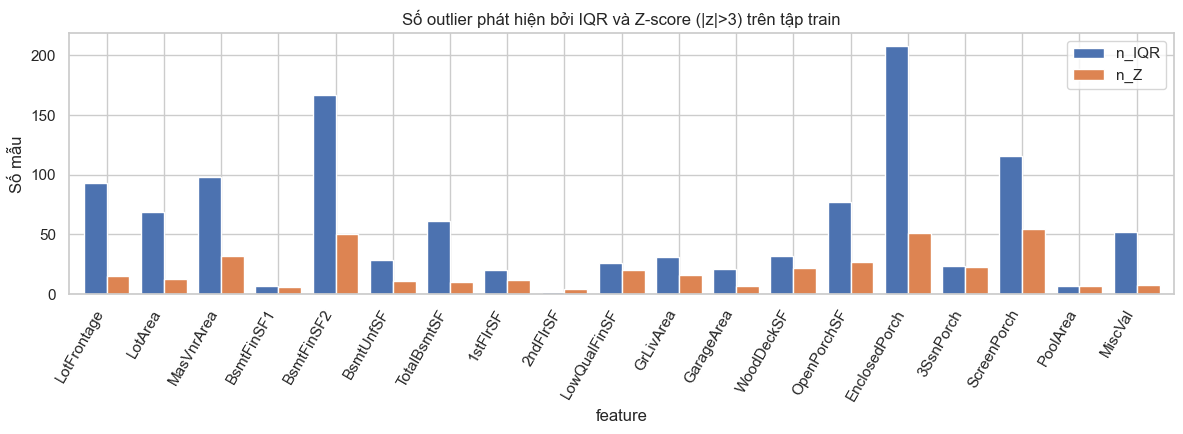

In [5]:
# Biến "lõi": IQR > 0 -> IQR/Z-score có ý nghĩa; biến zero-inflated (IQR = 0) xử lý riêng
core_cols = out_tab.index[out_tab.IQR > 0].tolist()
zero_infl = out_tab.index[out_tab.IQR == 0].tolist()
print('Biến lõi:', core_cols)
print('Zero-inflated (IQR = 0):', zero_infl)
R['core_cols'], R['zero_infl'] = core_cols, zero_infl

ax = out_tab[['n_IQR', 'n_Z']].plot(kind='bar', figsize=(12, 4.5), width=.8)
ax.set_title('Số outlier phát hiện bởi IQR và Z-score (|z|>3) trên tập train'); ax.set_ylabel('Số mẫu')
plt.xticks(rotation=60, ha='right'); savefig('fig01_iqr_vs_zscore.png')

## 2.2.3 Boxplot

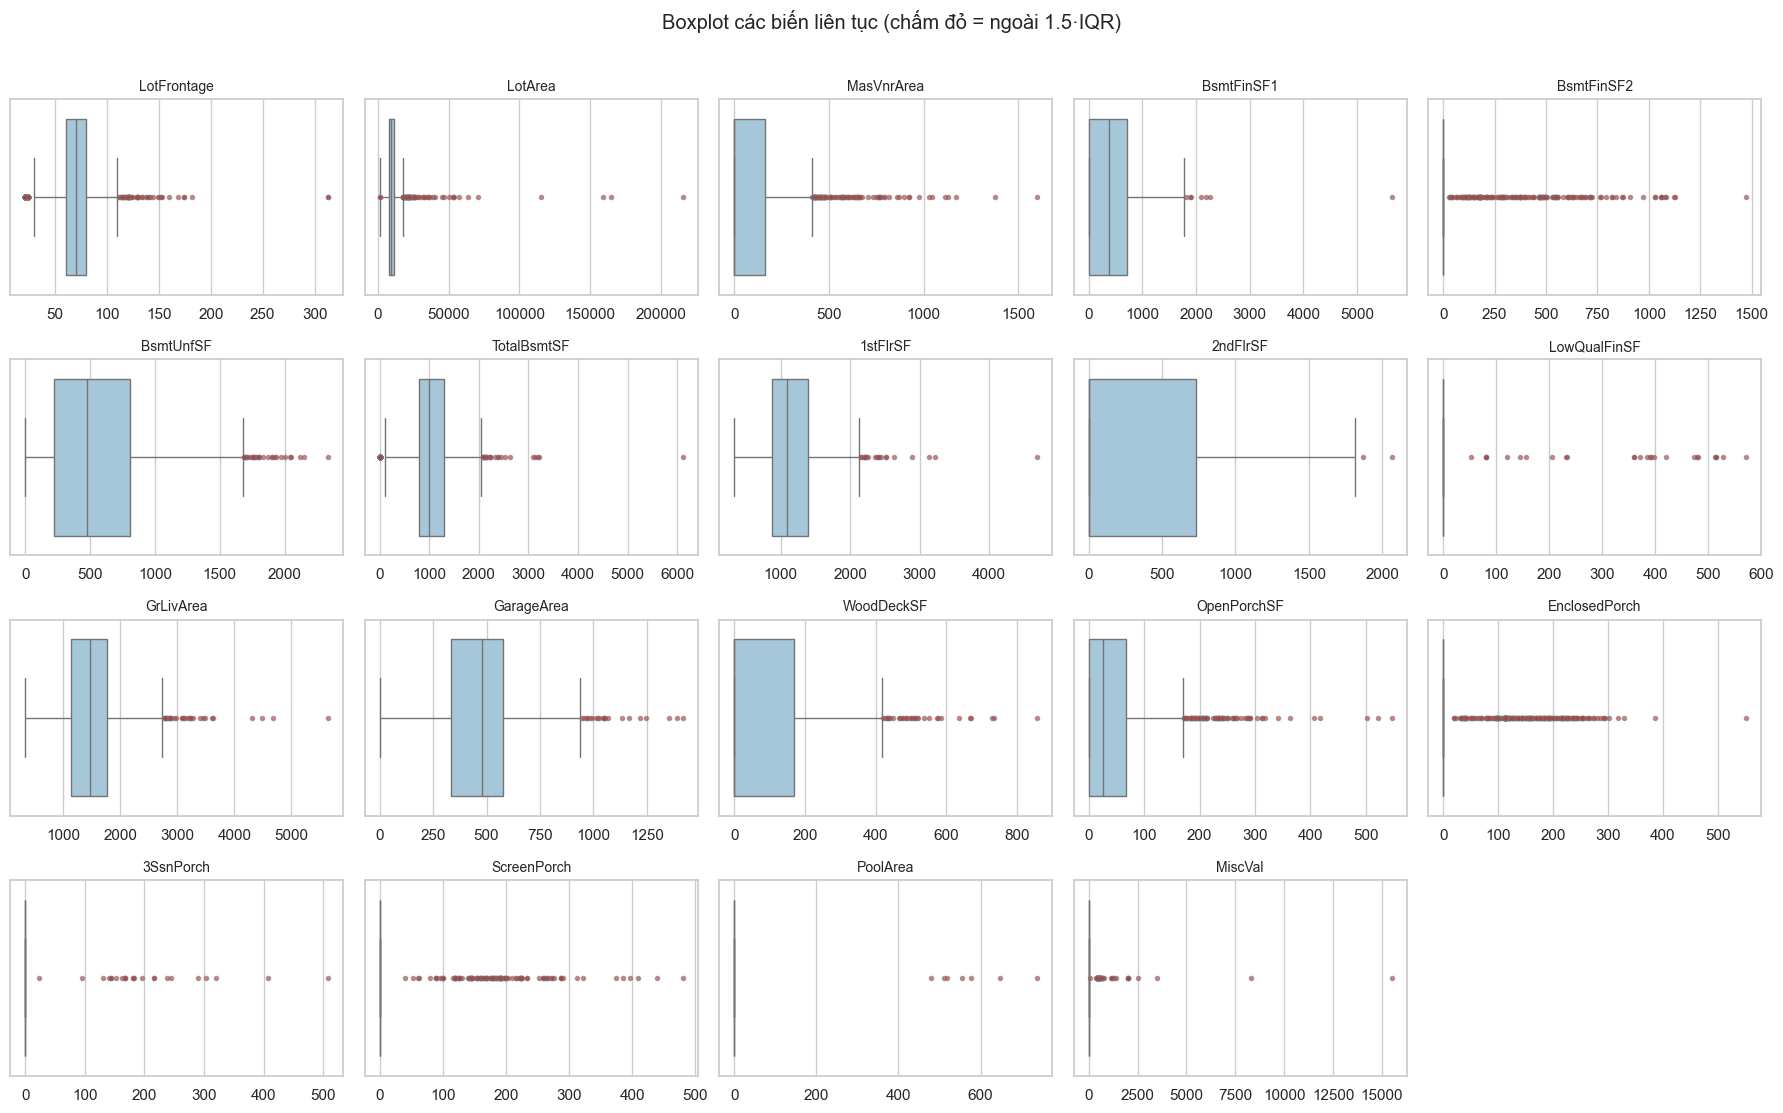

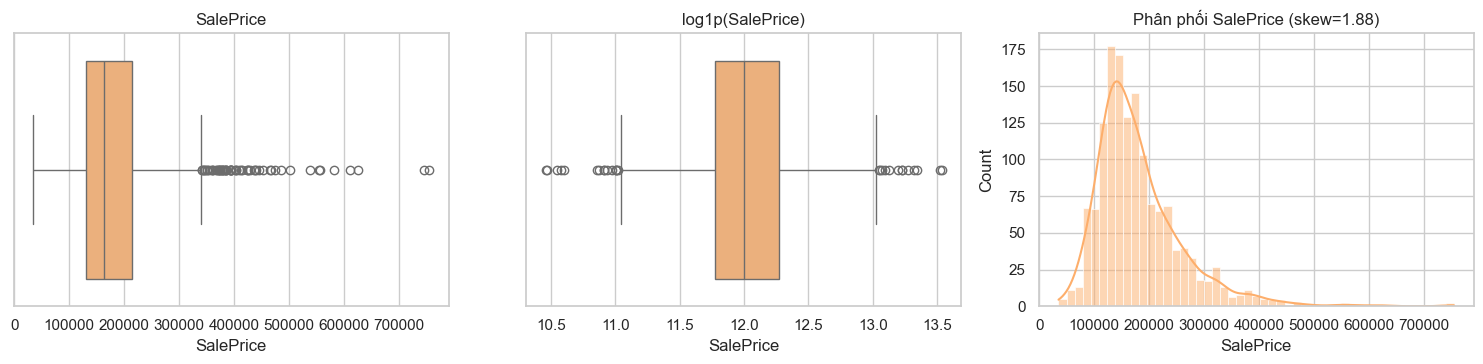

In [6]:
fig, axes = plt.subplots(4, 5, figsize=(18, 11))
for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(x=train[c], ax=ax, color='#9ecae1', flierprops=dict(marker='o', markersize=3, markerfacecolor='#d62728', alpha=.6))
    ax.set_title(c, fontsize=10); ax.set_xlabel('')
for ax in axes.ravel()[len(cont_cols):]: ax.axis('off')
plt.suptitle('Boxplot các biến liên tục (chấm đỏ = ngoài 1.5·IQR)', y=1.01); savefig('fig02_boxplots_features.png')

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=train[TARGET], ax=axes[0], color='#fdae6b'); axes[0].set_title('SalePrice')
sns.boxplot(x=np.log1p(train[TARGET]), ax=axes[1], color='#fdae6b'); axes[1].set_title('log1p(SalePrice)')
sns.histplot(train[TARGET], kde=True, ax=axes[2], color='#fdae6b'); axes[2].set_title(f'Phân phối SalePrice (skew={train[TARGET].skew():.2f})')
savefig('fig03_boxplot_saleprice.png')

## 2.2.4 Xác định những mẫu bất thường
Mỗi mẫu được đếm số biến lõi bị gắn cờ theo IQR và theo Z-score; mẫu bị gắn cờ ở nhiều biến cùng lúc, hoặc có kết hợp (diện tích, giá) phi logic, là ứng viên bất thường.

In [7]:
iqr_flag = pd.DataFrame({c: (train[c] < out_tab.loc[c,'lower']) | (train[c] > out_tab.loc[c,'upper']) for c in core_cols})
z_flag = pd.DataFrame({c: ((train[c] - train[c].mean()) / train[c].std()).abs() > 3 for c in core_cols})
flags = train[['Id','GrLivArea','TotalBsmtSF','LotArea','GarageArea','SalePrice','SaleCondition']].copy()
flags['n_flag_IQR'] = iqr_flag.sum(axis=1); flags['n_flag_Z'] = z_flag.sum(axis=1)

print('Số mẫu có ít nhất 1 cờ IQR :', (flags.n_flag_IQR >= 1).sum())
print('Số mẫu có ít nhất 1 cờ Z   :', (flags.n_flag_Z >= 1).sum())
print('Số mẫu có >= 3 cờ Z        :', (flags.n_flag_Z >= 3).sum())
R['n_rows_any_iqr'] = int((flags.n_flag_IQR >= 1).sum()); R['n_rows_any_z'] = int((flags.n_flag_Z >= 1).sum())
top = flags.sort_values(['n_flag_Z','n_flag_IQR'], ascending=False).head(10)
R['top_anomalies'] = top.to_dict('records')
top

Số mẫu có ít nhất 1 cờ IQR : 377
Số mẫu có ít nhất 1 cờ Z   : 116
Số mẫu có >= 3 cờ Z        : 13


,Id,GrLivArea,TotalBsmtSF,LotArea,GarageArea,SalePrice,SaleCondition,n_flag_IQR,n_flag_Z
1298,1299,5642,6110,63887,1418,160000,Partial,9,9
523,524,4676,3138,40094,884,184750,Partial,8,6
1182,1183,4476,2396,15623,813,745000,Abnorml,6,6
691,692,4316,2444,21535,832,755000,Normal,6,5
224,225,2392,2392,13472,968,386250,Normal,5,4
496,497,3228,3200,12692,546,430000,Normal,4,4
178,179,2234,2216,17423,1166,501837,Partial,5,3
769,770,3279,1650,53504,841,538000,Normal,4,3
898,899,2364,2330,12919,820,611657,Partial,4,3
1169,1170,3627,1930,35760,807,625000,Normal,4,3


In [8]:
# Phân tích đa biến: diện tích sinh hoạt lớn bất thường so với giá
big = train.loc[train.GrLivArea > 4000, ['Id','GrLivArea','TotalBsmtSF','LotArea','OverallQual','SaleCondition','SalePrice']]
print(big.to_string(index=False))
anom_mask = (train.GrLivArea > 4000) & (train.SalePrice < 300000)
print('\nMẫu bất thường thực sự (GrLivArea>4000 & SalePrice<300k): Id =', train.loc[anom_mask, 'Id'].tolist())
R['anom_ids'] = train.loc[anom_mask, 'Id'].tolist()
R['big_table'] = big.to_dict('records')

  Id  GrLivArea  TotalBsmtSF  LotArea  OverallQual SaleCondition  SalePrice
 524       4676         3138    40094           10       Partial     184750
 692       4316         2444    21535           10        Normal     755000
1183       4476         2396    15623           10       Abnorml     745000
1299       5642         6110    63887           10       Partial     160000

Mẫu bất thường thực sự (GrLivArea>4000 & SalePrice<300k): Id = [524, 1299]


**Nhận xét:** 4 căn có `GrLivArea > 4000`. Hai căn Id 692 và 1183 có `OverallQual` rất cao và giá ~750k → *cực đoan nhưng hợp lý* (nhà cao cấp). Hai căn Id 524 và 1299 diện tích 4676 và 5642 ft² nhưng chỉ bán 185k và 160k, đều thuộc `SaleCondition = Partial` (bán khi chưa hoàn thiện) → giá không phản ánh đúng diện tích, đây là **mẫu bất thường thực sự**. Tài liệu mô tả bộ dữ liệu Ames cũng khuyến nghị loại các căn này.

## 2.2.5 Đánh giá ảnh hưởng của outlier đến SalePrice
Bốn góc nhìn: (a) thay đổi hệ số tương quan khi bỏ outlier; (b) giá của nhóm outlier so với nhóm thường; (c) độ dốc/R² của hồi quy đơn biến; (d) thí nghiệm mô hình với các chiến lược xử lý khác nhau.

In [9]:
# (a) Tương quan Pearson với SalePrice: toàn bộ dữ liệu vs bỏ outlier IQR của chính biến đó
rows = []
for c in core_cols:
    m = ~iqr_flag[c]
    rows.append(dict(feature=c, corr_all=train[c].corr(train[TARGET]), corr_wo_outlier=train.loc[m, c].corr(train.loc[m, TARGET]), n_removed=int((~m).sum())))
corr_tab = pd.DataFrame(rows).set_index('feature')
corr_tab['delta'] = corr_tab.corr_wo_outlier - corr_tab.corr_all
R['corr_table'] = corr_tab.round(4).reset_index().to_dict('records')
corr_tab.round(3)

,corr_all,corr_wo_outlier,n_removed,delta
feature,,,,
LotFrontage,0.350,0.369,93,0.019
LotArea,0.264,0.430,69,0.167
MasVnrArea,0.473,0.346,98,-0.127
BsmtFinSF1,0.386,0.381,7,-0.006
BsmtUnfSF,0.214,0.135,29,-0.080
TotalBsmtSF,0.614,0.614,61,0.001
1stFlrSF,0.606,0.609,20,0.004
2ndFlrSF,0.319,0.296,2,-0.023
GrLivArea,0.709,0.696,31,-0.012


In [10]:
# (b) Giá của nhóm có outlier và nhóm bình thường
grp = np.where(flags.n_flag_Z >= 1, 'Có outlier (Z>3)', 'Bình thường')
cmp_price = train.groupby(grp)[TARGET].agg(['count','mean','median','std']).round(0)
R['price_by_group'] = cmp_price.reset_index().rename(columns={'index':'group'}).to_dict('records')
print(cmp_price)
print('\nOutlier của chính SalePrice (IQR):', int(((train[TARGET] > train[TARGET].quantile(.75) + 1.5*stats.iqr(train[TARGET]))).sum()), 'mẫu giá cao')

                  count      mean    median       std
Bình thường        1344  172149.0  158000.0   66164.0
Có outlier (Z>3)    116  282556.0  258500.0  132764.0

Outlier của chính SalePrice (IQR): 61 mẫu giá cao


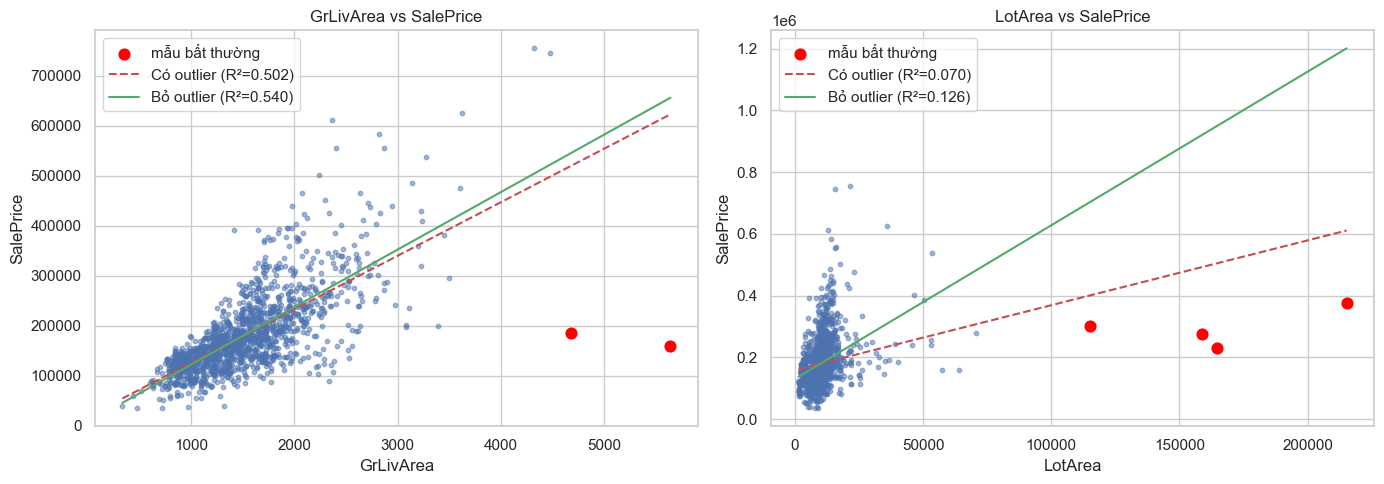

,slope_all,r2_all,slope_clean,r2_clean,n_out
GrLivArea,107.1304,0.5021,115.0400,0.5402,2.0
LotArea,2.1000,0.0696,4.9749,0.1257,4.0


In [11]:
# (c) Hồi quy đơn biến GrLivArea -> SalePrice và LotArea -> SalePrice
def fit_line(df, x):
    lr = LinearRegression().fit(df[[x]], df[TARGET]); return lr, lr.score(df[[x]], df[TARGET])

res = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, mask_out, title) in zip(axes, [('GrLivArea', anom_mask, 'GrLivArea'), ('LotArea', train.LotArea > 100000, 'LotArea')]):
    all_lr, all_r2 = fit_line(train, x)
    cl_lr, cl_r2 = fit_line(train[~mask_out], x)
    res[x] = dict(slope_all=all_lr.coef_[0], r2_all=all_r2, slope_clean=cl_lr.coef_[0], r2_clean=cl_r2, n_out=int(mask_out.sum()))
    ax.scatter(train.loc[~mask_out, x], train.loc[~mask_out, TARGET], s=10, alpha=.5)
    ax.scatter(train.loc[mask_out, x], train.loc[mask_out, TARGET], s=60, c='red', label='mẫu bất thường')
    xs = np.linspace(train[x].min(), train[x].max(), 100)
    ax.plot(xs, all_lr.predict(pd.DataFrame({x: xs})), 'r--', label=f'Có outlier (R²={all_r2:.3f})')
    ax.plot(xs, cl_lr.predict(pd.DataFrame({x: xs})), 'g-', label=f'Bỏ outlier (R²={cl_r2:.3f})')
    ax.set_title(f'{title} vs SalePrice'); ax.set_xlabel(x); ax.set_ylabel(TARGET); ax.legend()
savefig('fig04_impact_scatter.png')
R['regression_impact'] = res
pd.DataFrame(res).T.round(4)

In [12]:
# (d) Thí nghiệm mô hình: Ridge trên biến số (đã chuẩn hóa), mục tiêu log1p(SalePrice), CV 5 fold x 3 lần
num_all = [c for c in train.select_dtypes('number').columns if c not in ['Id', TARGET]]
y = np.log1p(train[TARGET])

def fit_caps(df, cols, k=3.0):
    q1, q3 = df[cols].quantile(.25), df[cols].quantile(.75); i = q3 - q1
    return q1 - k*i, q3 + k*i

def run_strategy(name):
    r_all, r_clean = [], []
    for tr_i, va_i in RepeatedKFold(n_splits=5, n_repeats=3, random_state=42).split(train):
        Xtr, ytr = train.iloc[tr_i][num_all].copy(), y.iloc[tr_i]
        Xva, yva = train.iloc[va_i][num_all].copy(), y.iloc[va_i]
        if name in ('B', 'C'):
            keep = ~anom_mask.iloc[tr_i].values; Xtr, ytr = Xtr[keep], ytr[keep]
        if name == 'C':
            lo, hi = fit_caps(Xtr, core_cols)
            Xtr[core_cols] = Xtr[core_cols].clip(lower=lo, upper=hi, axis=1)
            Xva[core_cols] = Xva[core_cols].clip(lower=lo, upper=hi, axis=1)
        if name == 'D':   # xóa mọi dòng có |z|>3 ở bất kỳ biến lõi nào
            z = ((Xtr[core_cols] - Xtr[core_cols].mean()) / Xtr[core_cols].std()).abs() > 3
            keep = ~z.any(axis=1).values; Xtr, ytr = Xtr[keep], ytr[keep]
        sc = StandardScaler().fit(Xtr); mdl = Ridge(alpha=10).fit(sc.transform(Xtr), ytr)
        pred = mdl.predict(sc.transform(Xva))
        r_all.append(np.sqrt(np.mean((pred - yva) ** 2)))
        ok = ~anom_mask.iloc[va_i].values
        r_clean.append(np.sqrt(np.mean((pred[ok] - yva.values[ok]) ** 2)))
    return np.mean(r_all), np.mean(r_clean)

names = {'A': 'A. Giữ nguyên', 'B': 'B. Xóa 2 mẫu bất thường', 'C': 'C. B + cắt ngưỡng (winsorize 3·IQR)', 'D': 'D. Xóa mọi dòng có |z|>3'}
exp = pd.DataFrame({names[k]: run_strategy(k) for k in names}, index=['RMSE(log) - mọi mẫu validation', 'RMSE(log) - bỏ 2 mẫu bất thường']).T.round(4)
# số dòng bị xóa bởi D (trên toàn train)
zD = ((train[core_cols] - train[core_cols].mean()) / train[core_cols].std()).abs() > 3
R['rows_removed_D'] = int(zD.any(axis=1).sum())
R['strategy_table'] = exp.reset_index().rename(columns={'index': 'strategy'}).to_dict('records')
print('Chiến lược D sẽ xóa', R['rows_removed_D'], 'dòng /', len(train))
exp

Chiến lược D sẽ xóa 116 dòng / 1460


,RMSE(log) - mọi mẫu validation,RMSE(log) - bỏ 2 mẫu bất thường
A. Giữ nguyên,0.1584,0.1376
B. Xóa 2 mẫu bất thường,0.1531,0.1291
C. B + cắt ngưỡng (winsorize 3·IQR),0.1407,0.1276
D. Xóa mọi dòng có |z|>3,0.1591,0.1326


## 2.2.6 Lựa chọn phương pháp xử lý và lý do
| Nhóm | Xử lý | Lý do |
|---|---|---|
| 2 mẫu Id 524, 1299 (diện tích cực lớn nhưng giá thấp, `Partial`) | **Xóa khỏi train** | Làm lệch đường hồi quy (xem hình 4), là mẫu có quan hệ diện tích–giá không đại diện cho thị trường. Chỉ 2/1460 mẫu nên mất mát thông tin không đáng kể. |
| Giá trị cực đoan còn lại ở các biến lõi (IQR > 0) | **Winsorize (cắt ngưỡng) ở `Q1 − 3·IQR` / `Q3 + 3·IQR`**, ngưỡng học từ train, áp dụng cho cả test | Giữ nguyên số mẫu, giảm ảnh hưởng của giá trị cực đoan lên mô hình tuyến tính và scaler. Dùng 3·IQR (ngưỡng "extreme") thay vì 1.5·IQR để chỉ chạm vào các điểm thật sự xa. |
| Biến zero-inflated (IQR = 0: `PoolArea`, `3SsnPorch`, `MiscVal`...) | **Giữ nguyên** | Giá trị khác 0 là thông tin thật (có hồ bơi, có hiên...), không phải lỗi. |
| Outlier của `SalePrice` (nhà giá cao) | **Giữ nguyên** | Là các căn cao cấp hợp lệ (Id 692, 1183...); xóa sẽ làm mô hình không dự đoán được phân khúc này. |
| Xóa mọi dòng có \|z\|>3 (chiến lược D) | **Không dùng** | Mất quá nhiều dòng và loại cả các mẫu hợp lệ. |

Kết quả thí nghiệm ở mục (d) được dùng để đối chiếu lựa chọn này.

In [13]:
# ÁP DỤNG XỬ LÝ OUTLIER
train_c = train.loc[~anom_mask].copy().reset_index(drop=True)
test_c = test.copy()
lo, hi = fit_caps(train_c, core_cols, k=3.0)
capped_train = ((train_c[core_cols] < lo) | (train_c[core_cols] > hi)).sum()
capped_test = ((test_c[core_cols] < lo) | (test_c[core_cols] > hi)).sum()
R['capped'] = pd.DataFrame({'train': capped_train, 'test': capped_test}).reset_index().rename(columns={'index': 'feature'}).to_dict('records')
before = train_c[core_cols].copy()
for df in (train_c, test_c):
    df[core_cols] = df[core_cols].clip(lower=lo, upper=hi, axis=1)
print('Train sau khi xóa:', train_c.shape, '| số giá trị bị cắt (train/test):', int(capped_train.sum()), '/', int(capped_test.sum()))
pd.DataFrame({'lower_cap': lo, 'upper_cap': hi, 'capped_train': capped_train, 'capped_test': capped_test}).round(1)

Train sau khi xóa: (1458, 81) | số giá trị bị cắt (train/test): 97 / 86


,lower_cap,upper_cap,capped_train,capped_test
LotFrontage,0.0,140.0,12,7
LotArea,-4622.0,23766.5,32,19
MasVnrArea,-491.2,655.0,26,28
BsmtFinSF1,-2133.0,2844.0,0,1
BsmtUnfSF,-1532.0,2563.0,0,0
TotalBsmtSF,-709.2,2801.2,3,2
1stFlrSF,-644.2,2917.0,1,2
2ndFlrSF,-2184.0,2912.0,0,0
GrLivArea,-814.0,3718.5,2,2
GarageArea,-402.0,1309.5,2,3


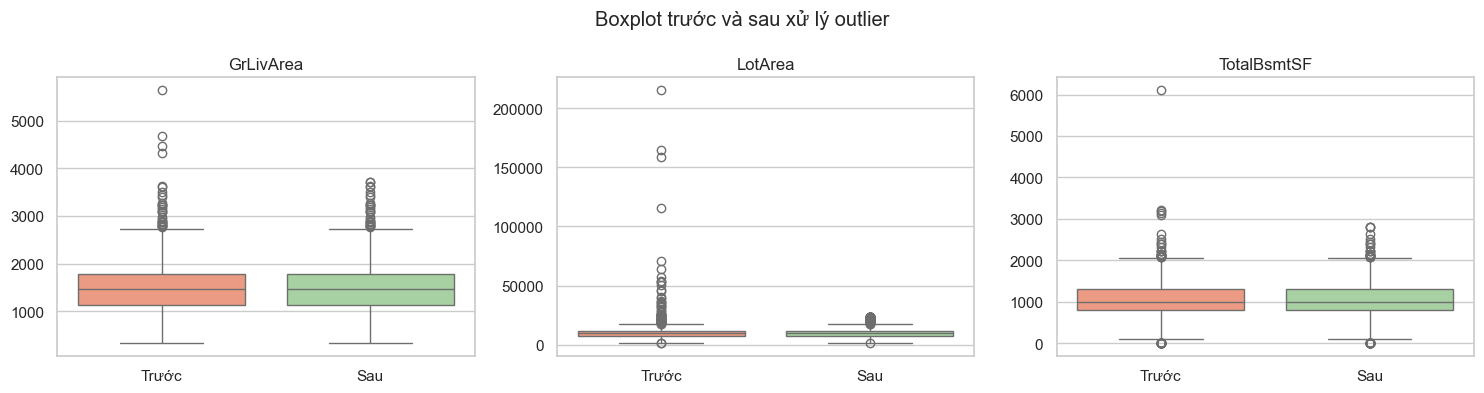

In [14]:
# So sánh trước/sau xử lý outlier
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['GrLivArea', 'LotArea', 'TotalBsmtSF']):
    d = pd.DataFrame({'Trước': train[c], 'Sau': train_c[c]})
    sns.boxplot(data=d, ax=ax, palette=['#fc9272', '#a1d99b']); ax.set_title(c)
plt.suptitle('Boxplot trước và sau xử lý outlier'); savefig('fig05_before_after_outlier.png')

---
# 2.3 Categorical Data
## 2.3.1 Phân loại Nominal và Ordinal
- **Ordinal:** các giá trị có thứ tự rõ ràng (chất lượng Ex > Gd > TA > Fa > Po, mức độ hoàn thiện, độ dốc...). Mã hóa thành số nguyên **giữ đúng thứ tự**.
- **Nominal:** không có thứ tự (khu phố, kiểu mái, loại móng...). Dùng One-Hot để không áp đặt thứ tự giả.
- `MSSubClass` và `MoSold` là số nhưng thực chất là **mã danh mục** → ép sang chuỗi và xử lý như nominal.
- `OverallQual`, `OverallCond` (1–10) đã là ordinal dạng số → giữ nguyên.

In [15]:
qual = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_maps = {
    'ExterQual': qual, 'ExterCond': qual, 'BsmtQual': qual, 'BsmtCond': qual, 'HeatingQC': qual,
    'KitchenQual': qual, 'FireplaceQu': qual, 'GarageQual': qual, 'GarageCond': qual, 'PoolQC': qual,
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
    'Functional': {'Sal': 0, 'Sev': 1, 'Maj2': 2, 'Maj1': 3, 'Mod': 4, 'Min2': 5, 'Min1': 6, 'Typ': 7},
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
    'LotShape': {'IR3': 0, 'IR2': 1, 'IR1': 2, 'Reg': 3},
    'LandSlope': {'Sev': 0, 'Mod': 1, 'Gtl': 2},
    'PavedDrive': {'N': 0, 'P': 1, 'Y': 2},
    'Fence': {'None': 0, 'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'Utilities': {'ELO': 0, 'NoSeWa': 1, 'NoSeWr': 2, 'AllPub': 3},
}
for df in (train_c, test_c):
    df['MSSubClass'] = df['MSSubClass'].astype(str); df['MoSold'] = df['MoSold'].astype(str)

obj_cols = train_c.select_dtypes(exclude='number').columns.tolist()
nominal_cols = [c for c in obj_cols if c not in ordinal_maps]
ordinal_cols = list(ordinal_maps)
print(f'Ordinal: {len(ordinal_cols)} cột | Nominal: {len(nominal_cols)} cột')
cls = pd.DataFrame(
    [dict(column=c, type='Ordinal', n_categories=train_c[c].nunique(), order=' < '.join(ordinal_maps[c])) for c in ordinal_cols] +
    [dict(column=c, type='Nominal', n_categories=train_c[c].nunique(), order='-') for c in nominal_cols])
R['cat_classification'] = cls.to_dict('records')
cls

Ordinal: 20 cột | Nominal: 25 cột


,column,type,n_categories,order
0,ExterQual,Ordinal,4,None < Po < Fa < TA < Gd < Ex
1,ExterCond,Ordinal,5,None < Po < Fa < TA < Gd < Ex
2,BsmtQual,Ordinal,5,None < Po < Fa < TA < Gd < Ex
3,BsmtCond,Ordinal,5,None < Po < Fa < TA < Gd < Ex
4,HeatingQC,Ordinal,5,None < Po < Fa < TA < Gd < Ex
5,KitchenQual,Ordinal,4,None < Po < Fa < TA < Gd < Ex
6,FireplaceQu,Ordinal,6,None < Po < Fa < TA < Gd < Ex
7,GarageQual,Ordinal,6,None < Po < Fa < TA < Gd < Ex
8,GarageCond,Ordinal,6,None < Po < Fa < TA < Gd < Ex
9,PoolQC,Ordinal,4,None < Po < Fa < TA < Gd < Ex


## 2.3.2 Ordinal Encoding

In [16]:
def ordinal_encode(df):
    df = df.copy()
    for c, mp in ordinal_maps.items():
        df[c] = df[c].map(mp)
    return df

train_o, test_o = ordinal_encode(train_c), ordinal_encode(test_c)
print('NaN sau ordinal encoding (train/test):', train_o[ordinal_cols].isna().sum().sum(), '/', test_o[ordinal_cols].isna().sum().sum())

NaN sau ordinal encoding (train/test): 0 / 0


## 2.3.3 One-Hot Encoding

In [17]:
ohe = OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False).fit(train_o[nominal_cols])
def clean(n): return re.sub(r'[^0-9a-zA-Z]+', '_', n).strip('_')
ohe_names = [clean(n) for n in ohe.get_feature_names_out(nominal_cols)]
assert len(set(ohe_names)) == len(ohe_names)

def onehot(df):
    d = pd.DataFrame(ohe.transform(df[nominal_cols]), columns=ohe_names, index=df.index).astype('int8')
    return pd.concat([df.drop(columns=nominal_cols), d], axis=1)

train_e, test_e = onehot(train_o), onehot(test_o)
print('Số cột One-Hot tạo ra:', len(ohe_names))
print('Shape sau encoding -> train:', train_e.shape, '| test:', test_e.shape)
R['shape_encoded'] = {'train': list(train_e.shape), 'test': list(test_e.shape), 'n_ohe': len(ohe_names)}

Số cột One-Hot tạo ra: 193
Shape sau encoding -> train: (1458, 249) | test: (1459, 248)


## 2.3.4 Kiểm tra dữ liệu sau Encoding

In [18]:
checks = {}
feat_tr = train_e.drop(columns=TARGET)
checks['Không còn cột kiểu chữ (object)'] = int(feat_tr.select_dtypes(exclude='number').shape[1]) == 0
checks['Không còn NaN (train)'] = int(feat_tr.isna().sum().sum()) == 0
checks['Không còn NaN (test)'] = int(test_e.isna().sum().sum()) == 0
checks['Train và test cùng bộ cột'] = list(feat_tr.columns) == list(test_e.columns)
checks['Ordinal nằm trong miền hợp lệ'] = all(train_e[c].between(min(m.values()), max(m.values())).all() for c, m in ordinal_maps.items())

# Mỗi biến nominal (không nhị phân) phải có tổng các cột dummy = 1 trên mỗi dòng
ok_sum, unseen_test = True, {}
for c in nominal_cols:
    cols = [n for n in ohe_names if n.startswith(clean(c) + '_')]
    if train_c[c].nunique() > 2:
        ok_sum &= bool((train_e[cols].sum(axis=1) == 1).all())
        u = int((test_e[cols].sum(axis=1) == 0).sum())
        if u: unseen_test[c] = u
checks['Tổng dummy = 1 mỗi dòng (train)'] = ok_sum
R['checks'] = {k: bool(v) for k, v in checks.items()}; R['unseen_test'] = unseen_test
print(pd.Series(checks).to_string())
print('\nDòng test có nhãn lạ chưa thấy ở train (được mã hóa toàn 0):', unseen_test)

Không còn cột kiểu chữ (object)    True
Không còn NaN (train)              True
Không còn NaN (test)               True
Train và test cùng bộ cột          True
Ordinal nằm trong miền hợp lệ      True
Tổng dummy = 1 mỗi dòng (train)    True

Dòng test có nhãn lạ chưa thấy ở train (được mã hóa toàn 0): {'MSSubClass': 1}


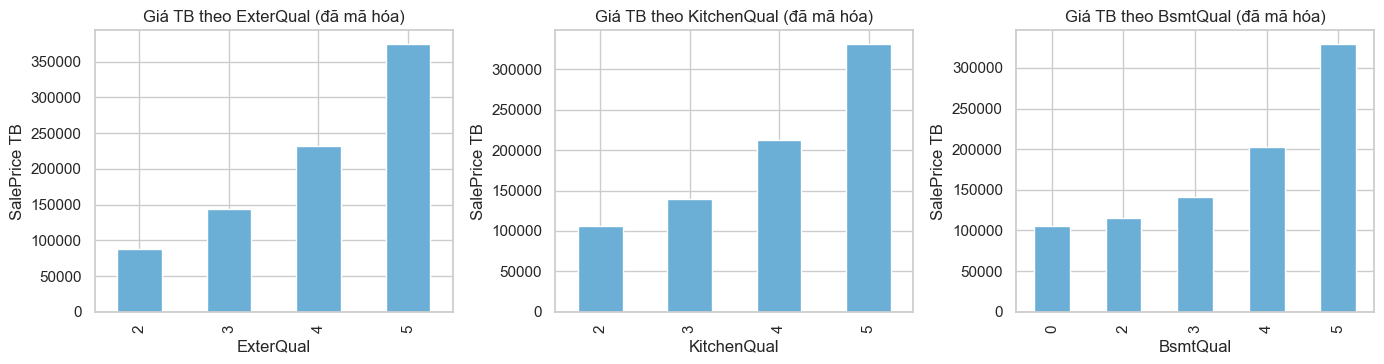

Các cột ordinal có giá TB tăng đơn điệu theo mã: ['ExterQual', 'BsmtQual', 'HeatingQC', 'KitchenQual', 'PoolQC', 'BsmtExposure', 'GarageFinish', 'PavedDrive', 'Utilities']
Các cột không đơn điệu (cần lưu ý): ['ExterCond', 'BsmtCond', 'FireplaceQu', 'GarageQual', 'GarageCond', 'BsmtFinType1', 'BsmtFinType2', 'Functional', 'LotShape', 'LandSlope', 'Fence']


In [19]:
# Kiểm tra thứ tự ordinal có hợp lý: giá trung bình phải tăng theo mức mã hóa
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, ['ExterQual', 'KitchenQual', 'BsmtQual']):
    train_e.groupby(c)[TARGET].mean().plot(kind='bar', ax=ax, color='#6baed6')
    ax.set_title(f'Giá TB theo {c} (đã mã hóa)'); ax.set_ylabel('SalePrice TB')
savefig('fig06_ordinal_check.png')
mono = {c: bool(train_e.groupby(c)[TARGET].mean().is_monotonic_increasing) for c in ordinal_cols}
R['ordinal_monotonic'] = mono
print('Các cột ordinal có giá TB tăng đơn điệu theo mã:', [c for c, v in mono.items() if v])
print('Các cột không đơn điệu (cần lưu ý):', [c for c, v in mono.items() if not v])

In [20]:
train_e.drop(columns='Id').head(3).T.head(12)

,0,1,2
LotFrontage,65.0,80.0,68.0
LotArea,8450.0,9600.0,11250.0
LotShape,3.0,3.0,2.0
Utilities,3.0,3.0,3.0
LandSlope,2.0,2.0,2.0
OverallQual,7.0,6.0,7.0
OverallCond,5.0,8.0,5.0
YearBuilt,2003.0,1976.0,2001.0
YearRemodAdd,2003.0,1976.0,2002.0
MasVnrArea,196.0,0.0,162.0


---
# 2.4 Numerical Data
## 2.4.1 Chọn scaler cho từng nhóm cột
| Nhóm | Scaler | Lý do |
|---|---|---|
| Biến liên tục, biến đếm, biến năm | **StandardScaler** | Đưa về mean=0, std=1; phù hợp mô hình tuyến tính/Ridge/Lasso, SVM, KNN, mạng nơ-ron. |
| Các cột ordinal đã mã hóa + `OverallQual/OverallCond` | **MinMaxScaler** (cần thiết) | Có miền giá trị hữu hạn, không phân phối chuẩn → đưa về [0, 1] giữ nguyên khoảng cách tương đối giữa các mức. |
| Cột One-Hot (0/1) | Không scale | Đã nằm trong [0, 1]. |
| `Id`, `SalePrice` | Không scale | Id không phải đặc trưng; SalePrice là biến mục tiêu (giữ giá trị gốc để dễ diễn giải). |

In [21]:
minmax_cols = ordinal_cols + ['OverallQual', 'OverallCond']
exclude = ['Id', TARGET] + ohe_names
standard_cols = [c for c in train_e.columns if c not in exclude + minmax_cols]
print('StandardScaler:', len(standard_cols), 'cột | MinMaxScaler:', len(minmax_cols), 'cột | One-Hot (giữ nguyên):', len(ohe_names))
R['n_scaled'] = {'standard': len(standard_cols), 'minmax': len(minmax_cols), 'ohe': len(ohe_names)}

std_sc = StandardScaler().fit(train_e[standard_cols])
mm_sc = MinMaxScaler().fit(train_e[minmax_cols])

def scale(df):
    df = df.copy()
    df[standard_cols] = std_sc.transform(df[standard_cols])
    df[minmax_cols] = mm_sc.transform(df[minmax_cols])
    return df

train_s, test_s = scale(train_e), scale(test_e)

StandardScaler: 32 cột | MinMaxScaler: 22 cột | One-Hot (giữ nguyên): 193


## 2.4.2 So sánh phân phối trước và sau chuẩn hóa

In [22]:
show = ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'YearBuilt', 'KitchenQual', 'OverallQual']
def stat(df, c): s = df[c]; return dict(mean=s.mean(), std=s.std(), min=s.min(), max=s.max(), skew=s.skew())
comp = pd.concat({'Trước': pd.DataFrame({c: stat(train_e, c) for c in show}).T,
                  'Sau (train)': pd.DataFrame({c: stat(train_s, c) for c in show}).T,
                  'Sau (test)': pd.DataFrame({c: stat(test_s, c) for c in show}).T}, axis=1).round(3)
R['scale_compare'] = {c: {k: {m: float(v) for m, v in comp.loc[c, k].items()} for k in ['Trước', 'Sau (train)', 'Sau (test)']} for c in show}
comp

Trước                                    Sau (train)         \
                 mean       std     min       max   skew        mean    std   
GrLivArea    1509.536   503.184   334.0   3718.50  0.901       0.000  1.000   
LotArea      9832.110  4124.712  1300.0  23766.50  0.980       0.000  1.000   
TotalBsmtSF  1051.785   411.458     0.0   2801.25  0.409      -0.000  1.000   
YearBuilt    1971.218    30.194  1872.0   2010.00 -0.612       0.000  1.000   
KitchenQual     3.510     0.662     2.0      5.00  0.384       0.503  0.221   
OverallQual     6.094     1.376     1.0     10.00  0.201       0.566  0.153   

                                 Sau (test)                              
               min    max   skew       mean    std    min    max   skew  
GrLivArea   -2.337  4.391  0.901     -0.049  0.953 -2.192  4.391  0.947  
LotArea     -2.069  3.379  0.980     -0.045  0.976 -2.028  3.379  0.804  
TotalBsmtSF -2.557  4.253  0.409     -0.019  1.053 -2.557  4.253  0.357  
YearBuilt   -3.287  1.285 -0.612      0.005  1.007 -3.055  1.285 -0.588  
KitchenQual  0.000  1.000  0.384      0.503  0.220  0.000  1.000  0.492  
OverallQual  0.000  1.000  0.201      0.564  0.160  0.000  1.000  0.181

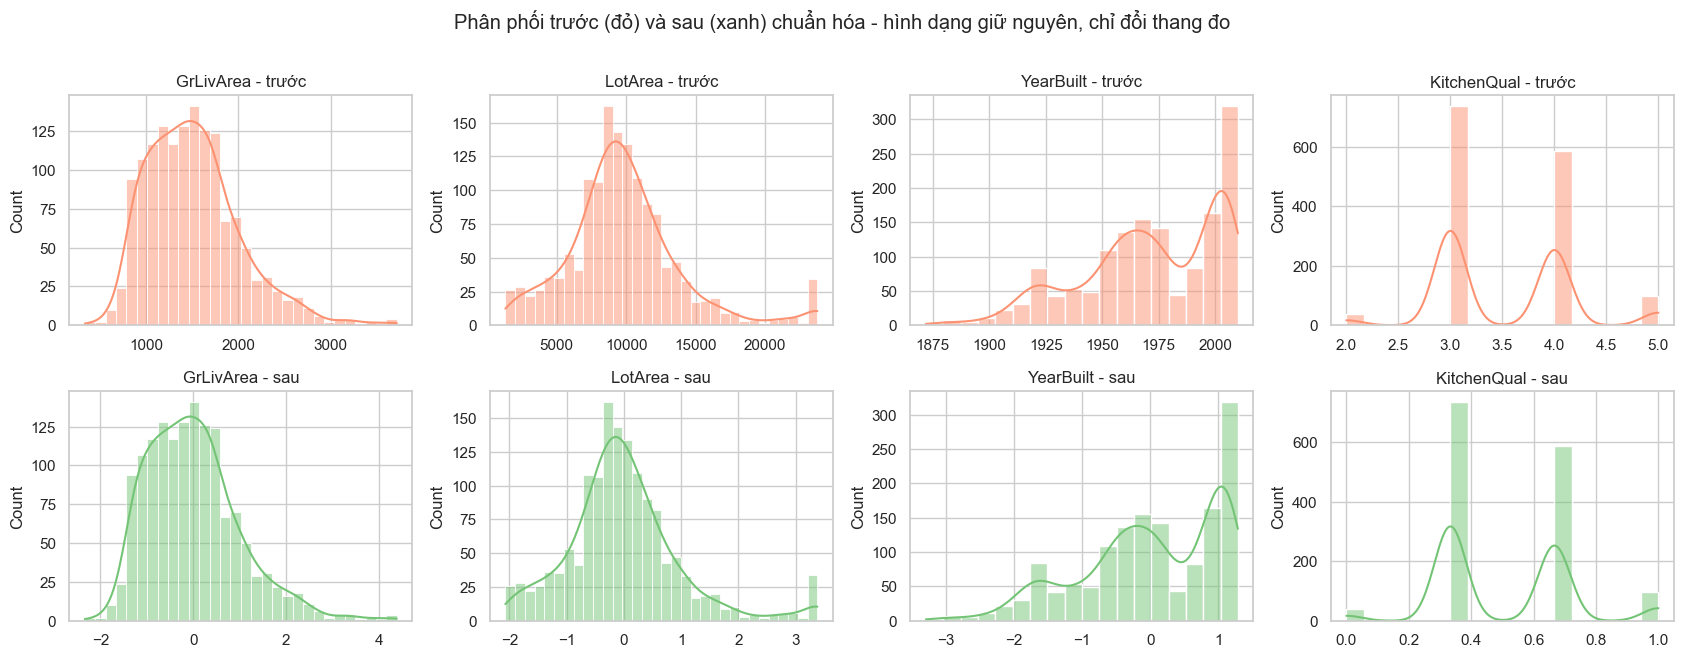

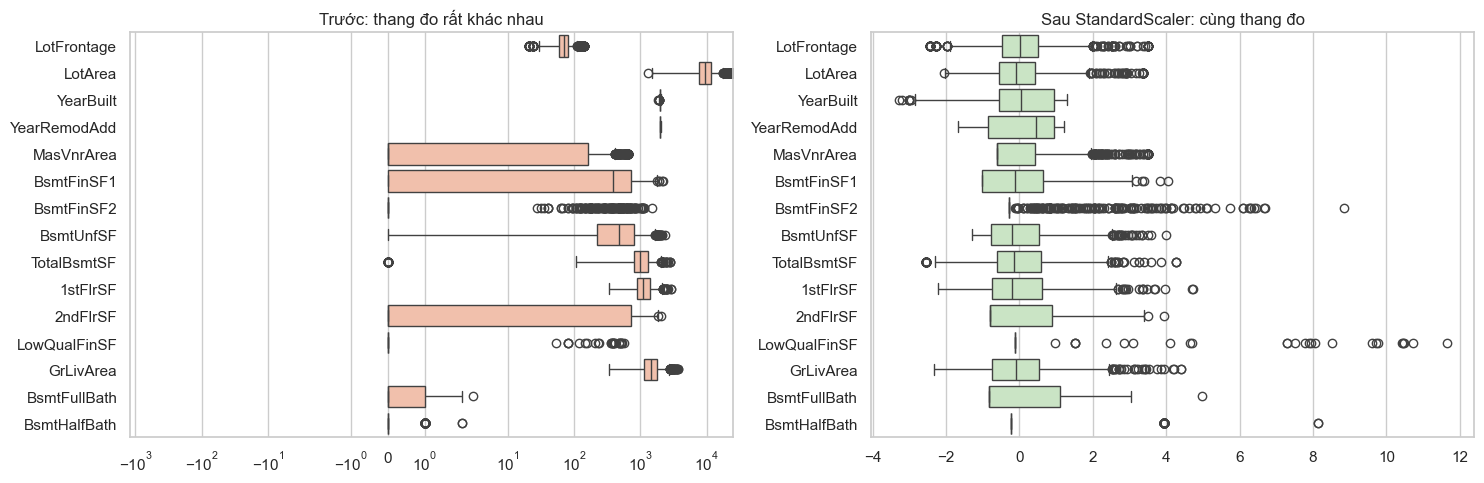

StandardScaler (train): |mean| max = 0.0 | std trong [ 1.0 , 1.0 ]
MinMax (train): min = 0.0 | max = 1.0
MinMax (test) : min = 0.0 | max = 1.0
Skew trung bình trước/sau: 2.862 / 2.862


In [23]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for j, c in enumerate(['GrLivArea', 'LotArea', 'YearBuilt', 'KitchenQual']):
    sns.histplot(train_e[c], kde=True, ax=axes[0, j], color='#fc9272'); axes[0, j].set_title(f'{c} - trước')
    sns.histplot(train_s[c], kde=True, ax=axes[1, j], color='#74c476'); axes[1, j].set_title(f'{c} - sau')
    axes[0, j].set_xlabel(''); axes[1, j].set_xlabel('')
plt.suptitle('Phân phối trước (đỏ) và sau (xanh) chuẩn hóa - hình dạng giữ nguyên, chỉ đổi thang đo', y=1.01)
savefig('fig07_scaling_hist.png')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=train_e[standard_cols[:15]], orient='h', ax=axes[0], color='#fcbba1'); axes[0].set_title('Trước: thang đo rất khác nhau'); axes[0].set_xscale('symlog')
sns.boxplot(data=train_s[standard_cols[:15]], orient='h', ax=axes[1], color='#c7e9c0'); axes[1].set_title('Sau StandardScaler: cùng thang đo')
savefig('fig08_scaling_box.png')

chk = pd.DataFrame({'mean': train_s[standard_cols].mean(), 'std': train_s[standard_cols].std(ddof=0)})
print('StandardScaler (train): |mean| max =', chk['mean'].abs().max().round(6), '| std trong [', chk['std'].min().round(3), ',', chk['std'].max().round(3), ']')
print('MinMax (train): min =', train_s[minmax_cols].min().min(), '| max =', train_s[minmax_cols].max().max())
print('MinMax (test) : min =', test_s[minmax_cols].min().min(), '| max =', test_s[minmax_cols].max().max())
print('Skew trung bình trước/sau:', round(train_e[standard_cols].skew().mean(), 3), '/', round(train_s[standard_cols].skew().mean(), 3))
R['scale_check'] = dict(mean_abs_max=float(chk['mean'].abs().max()), std_min=float(chk['std'].min()), std_max=float(chk['std'].max()),
                        mm_train=[float(train_s[minmax_cols].min().min()), float(train_s[minmax_cols].max().max())],
                        mm_test=[float(test_s[minmax_cols].min().min()), float(test_s[minmax_cols].max().max())],
                        skew_before=float(train_e[standard_cols].skew().mean()), skew_after=float(train_s[standard_cols].skew().mean()))

**Nhận xét:** chuẩn hóa chỉ thay đổi *thang đo* (mean, std, min, max), **không làm thay đổi hình dạng phân phối** — độ lệch (skewness) giữ nguyên. Nếu cần phân phối gần chuẩn hơn cho các biến lệch phải mạnh (`LotArea`, `GrLivArea`...), có thể bổ sung `log1p` hoặc `PowerTransformer` trước khi scale; ở đây chưa áp dụng vì ngoài phạm vi yêu cầu và các mô hình cây không cần.

---
# 3. Sản phẩm: dataset đã tiền xử lý
Xuất hai bản: **bản đã scale** (dùng cho mô hình tuyến tính, SVM, KNN, NN) và **bản chỉ encoding, chưa scale** (dùng cho mô hình cây).

In [24]:
train_s.to_csv(OUT_DIR / 'train_processed.csv', index=False)
test_s.to_csv(OUT_DIR / 'test_processed.csv', index=False)
train_e.to_csv(OUT_DIR / 'train_encoded_unscaled.csv', index=False)
test_e.to_csv(OUT_DIR / 'test_encoded_unscaled.csv', index=False)

feat = train_s.drop(columns=['Id', TARGET])
final = {
    'Không NaN/inf (train)': bool(np.isfinite(feat.values).all()),
    'Không NaN/inf (test)': bool(np.isfinite(test_s.drop(columns='Id').values).all()),
    'Toàn bộ cột là số': feat.select_dtypes(exclude='number').shape[1] == 0,
    'Train/test cùng bộ cột đặc trưng': list(feat.columns) == [c for c in test_s.columns if c != 'Id'],
}
print(pd.Series(final).to_string())
print('\ntrain_processed:', train_s.shape, '| test_processed:', test_s.shape, '| số đặc trưng:', feat.shape[1])
R['final_shape'] = {'train': list(train_s.shape), 'test': list(test_s.shape), 'n_features': feat.shape[1]}
R['final_checks'] = {k: bool(v) for k, v in final.items()}

# Smoke test: mô hình chạy trực tiếp trên dataset
yl = np.log1p(train_s[TARGET]); cv = KFold(5, shuffle=True, random_state=42)
smoke = {}
for name, mdl, X in [('Ridge (bản scale)', Ridge(alpha=10), feat),
                     ('RandomForest (bản chưa scale)', RandomForestRegressor(200, random_state=42, n_jobs=-1), train_e.drop(columns=['Id', TARGET]))]:
    smoke[name] = float(-cross_val_score(mdl, X, yl, cv=cv, scoring='neg_root_mean_squared_error').mean())
R['smoke_test'] = smoke
print('\nRMSE (log) CV 5-fold:', {k: round(v, 4) for k, v in smoke.items()})

Không NaN/inf (train)               True
Không NaN/inf (test)                True
Toàn bộ cột là số                   True
Train/test cùng bộ cột đặc trưng    True

train_processed: (1458, 249) | test_processed: (1459, 248) | số đặc trưng: 247

RMSE (log) CV 5-fold: {'Ridge (bản scale)': 0.1164, 'RandomForest (bản chưa scale)': 0.138}


In [26]:
with open(OUT_DIR / 'results.json', 'w', encoding='utf-8') as f:
    json.dump(
        R,
        f,
        ensure_ascii=False,
        indent=1,
        default=lambda o: o.item() if hasattr(o, 'item') else str(o)
    )

print('Đã lưu:', sorted(p.name for p in OUT_DIR.glob('*.csv')))

Đã lưu: ['test_encoded_unscaled.csv', 'test_processed.csv', 'train_encoded_unscaled.csv', 'train_processed.csv']


In [27]:
print("Các biến hiện có:")
print([name for name in ['X', 'y', 'X_train', 'X_test', 'y_train', 'y_test'] if name in globals()])

Các biến hiện có:
['X', 'y']


In [28]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nCác feature:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X shape: (1458, 247)
y shape: (1460,)

Các feature:
['LotFrontage', 'LotArea', 'LotShape', 'Utilities', 'LandSlope', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'HeatingQC', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC', 'Fence', 'MiscVal', 'YrSold', 'MSSubClass_120', 'MSSubClass_160', 'MSSubClass_180', 'MSSubClass_190', 'MSSubClass_20', 'MSSubClass_30', 'MSSubClass_40', 'MSSubClass_45', 'MSSubClass_50', 'MSSubClass_60', 'MSSubClass_70', 'MSSubClas